# Phase II Assignment
### Hank Eichstaedt

- Motivation
- Methods
- Results
- Discussion

## Setting up

Libraries and gathering our larger data sets

In [50]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [60]:
player_play = pd.read_csv("data/player_play.csv")
game_tracking_2023 = pd.read_csv("data/game_tracking_2023.csv")
combine_results = pd.read_csv("data/combine_results.csv")
combine_tracking = pd.read_csv("data/combine_tracking.csv")

### Note

Here I am only collecting data from 2023. This will make my data set smaller as I am missing two years. This is simply for the start of Phase II as I work through, later projects will have more data

# Concept One: Force

Sir Isaac Newton invented the force equation, `F = m * a` when he coined his Second Law of Motion. Who am I to say this isn't a viable metric for measuring offensive linemen?

In [12]:
oline = combine_results.loc[
    (combine_results['combine_position'] == 'OL'),
    ['nfl_id', 'combine_weight']
]

oline['weight'] = oline['combine_weight'] / 2.20462 # Convert to kg

In [32]:
passing = player_play.loc[
    (player_play['lined_up_position'] == 'T') |
    (player_play['lined_up_position'] == 'G') |
    (player_play['lined_up_position'] == 'C'),
    ['game_id', 'play_id', 'nfl_id', 'lined_up_position', 'pass_result']
]

passing = passing[passing['pass_result'].notna()]

passing = passing.drop_duplicates(
    subset=['game_id', 'play_id', 'nfl_id']
) # Make sure no duplicate values

In [20]:
oline_tracking = game_tracking_2023.merge(
    oline[['nfl_id', 'weight']],
    on='nfl_id',
    how='inner'
)

# This gives us 37 OL from the 2023 season

Sort by game, play, and time so all plays are in a row based on who we are tracking

In [21]:
oline_tracking = oline_tracking.sort_values(
    ['game_id', 'play_id', 'time']
).copy()

In [23]:
oline_tracking['row_num'] = (
    oline_tracking.groupby(['game_id', 'play_id']).cumcount()
)

# identify when snap occurs
snap_rows = (
    oline_tracking[oline_tracking['event'] == 'ball_snap']
    [['game_id', 'play_id', 'row_num']]
    .rename(columns={'row_num': 'snap_row'})
)

oline_tracking = oline_tracking.merge(
    snap_rows,
    on=['game_id', 'play_id'],
    how='left'
)

We are looking at the first three seconds for this df

In [25]:
first_three = oline_tracking[
    oline_tracking['row_num'].between(
        oline_tracking['snap_row'],
        oline_tracking['snap_row'] + 30
    )
].copy()

In [28]:
first_three = first_three.merge(
    passing[['game_id', 'play_id', 'nfl_id']],
    on=['game_id', 'play_id', 'nfl_id'],
    how='inner'
)

In [34]:
first_three['seconds_after_snap'] = (
    first_three['row_num'] - first_three['snap_row']
) * 0.1

In [40]:
time_groups = [1.0, 1.5, 2.0, 2.5, 3.0]

average_acceleration = []

for nfl_id, player_data in first_three.groupby('nfl_id'):

    for seconds in time_groups:

        group = player_data[
            player_data['seconds_after_snap'] <= seconds
        ]

        average_acceleration.append({
            'nfl_id': nfl_id,
            'Time Interval': f'0.0 - {seconds}',
            'Average Acceleration': group['a'].mean()
        })

average_acceleration_df = pd.DataFrame(average_acceleration)

In [46]:
average_acceleration_df = average_acceleration_df.merge(
    first_three[['nfl_id', 'weight']].drop_duplicates('nfl_id'),
    on='nfl_id',
    how='left'
)

In [48]:
average_acceleration_df['Force'] = (
    average_acceleration_df['Average Acceleration'] *
    average_acceleration_df['weight']
)

In [49]:
display(average_acceleration_df)

,nfl_id,Time Interval,Average Acceleration,weight,Force
0,55870,0.0 - 1.0,1.280815,141.974581,181.843141
1,55870,0.0 - 1.5,1.306912,141.974581,185.548272
2,55870,0.0 - 2.0,1.362772,141.974581,193.479046
3,55870,0.0 - 2.5,1.460420,141.974581,207.342473
4,55870,0.0 - 3.0,1.556020,141.974581,220.915340
...,...,...,...,...,...
180,56645,0.0 - 1.0,1.299506,145.149731,188.622886
181,56645,0.0 - 1.5,1.289627,145.149731,187.189040
182,56645,0.0 - 2.0,1.345565,145.149731,195.308377
183,56645,0.0 - 2.5,1.400522,145.149731,203.285397


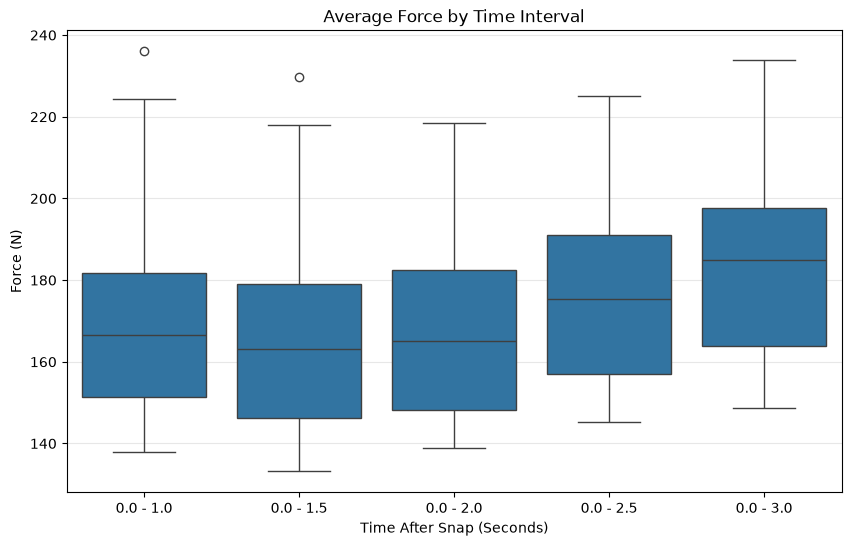

In [55]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=average_acceleration_df,
    x='Time Interval',
    y='Force'
)

plt.title('Average Force by Time Interval')
plt.xlabel('Time After Snap (Seconds)')
plt.ylabel('Force (N)')
plt.grid(axis='y', alpha=0.3)

plt.show()

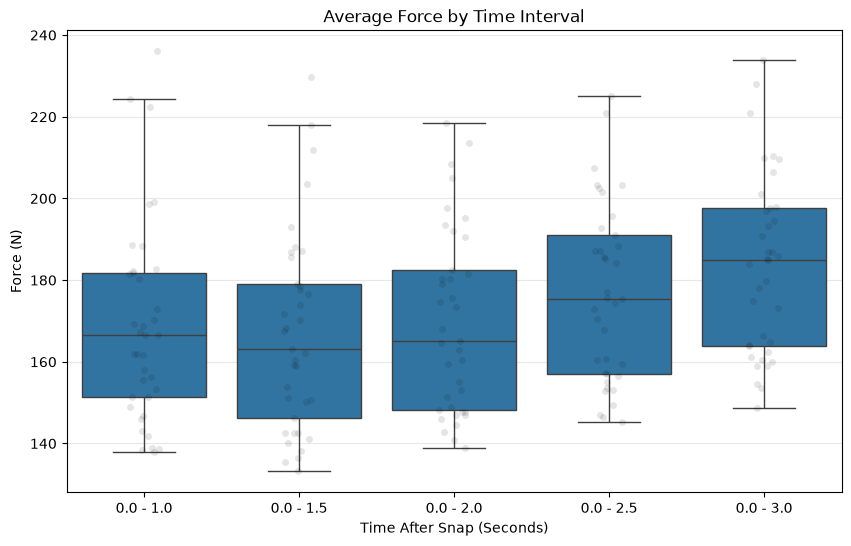

In [54]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=average_acceleration_df,
    x='Time Interval',
    y='Force',
    showfliers=False
)

sns.stripplot(
    data=average_acceleration_df,
    x='Time Interval',
    y='Force',
    color='black',
    alpha=0.1
    ,
    jitter=True
)

plt.title('Average Force by Time Interval')
plt.xlabel('Time After Snap (Seconds)')
plt.ylabel('Force (N)')
plt.grid(axis='y', alpha=0.3)

plt.show()

In [58]:
force_stats = average_acceleration_df.groupby('Time Interval')['Force'].describe()

force_stats

,count,mean,std,min,25%,50%,75%,max
Time Interval,,,,,,,,
0.0 - 1.0,37.0,168.630655,24.642492,137.879029,151.353272,166.483386,181.843141,235.980062
0.0 - 1.5,37.0,166.889366,24.392747,133.138947,146.200640,163.054285,178.988754,229.743297
0.0 - 2.0,37.0,169.761472,22.587359,138.965974,148.182648,164.998055,182.481432,218.438197
0.0 - 2.5,37.0,176.454340,21.817512,145.279346,156.991567,175.261756,190.970784,225.073600
0.0 - 3.0,37.0,183.467736,22.085450,148.622100,163.890686,184.935468,197.597743,233.802509


In [59]:
highest_force = average_acceleration_df.loc[
    average_acceleration_df.groupby('Time Interval')['Force'].idxmax()
]

lowest_force = average_acceleration_df.loc[
    average_acceleration_df.groupby('Time Interval')['Force'].idxmin()
]

print(lowest_force[['nfl_id', 'Time Interval', 'Force']])
print(highest_force[['nfl_id', 'Time Interval', 'Force']])

     nfl_id Time Interval       Force
170   56625     0.0 - 1.0  137.879029
116   56066     0.0 - 1.5  133.138947
137   56183     0.0 - 2.0  138.965974
138   56183     0.0 - 2.5  145.279346
114   56055     0.0 - 3.0  148.622100
    nfl_id Time Interval       Force
90   55983     0.0 - 1.0  235.980062
91   55983     0.0 - 1.5  229.743297
82   55976     0.0 - 2.0  218.438197
83   55976     0.0 - 2.5  225.073600
84   55976     0.0 - 3.0  233.802509


Now we know the stats for the actual players, lets look at the combine too.

The process will be very very similar

# Combine Drills

First we do the same filtering as before, but now we are testing off the combine drills

In [63]:
drills = combine_tracking.merge(
    oline[['nfl_id', 'weight']],
    on='nfl_id',
    how='inner'
)

In [68]:
drills = drills.sort_values(
    ['event_id', 'time']
).copy()

In [ ]:
drills = drills[drills['draft_year'] == 2023] # filter for this data set, so we can compare to our 2023 one

In [76]:
drills

,draft_year,event_id,nfl_id,entity_type,time,drill_type,drill_name,attempt,x,y,s,a,dis,dir,weight
57762,2023,6406869fe3d8e72dcdd1b8cb-2023,55901,PLAYER,2023-03-05T18:12:59.200,FORTY_YARD_DASH,FORTY_YARD_DASH,1,10.766667,-0.833333,0.620000,3.258849,0.001571,85.364537,150.592846
57763,2023,6406869fe3d8e72dcdd1b8cb-2023,55901,PLAYER,2023-03-05T18:12:59.300,FORTY_YARD_DASH,FORTY_YARD_DASH,1,10.866667,-0.833333,1.006667,3.789919,0.010000,85.441210,150.592846
57764,2023,6406869fe3d8e72dcdd1b8cb-2023,55901,PLAYER,2023-03-05T18:12:59.400,FORTY_YARD_DASH,FORTY_YARD_DASH,1,11.000000,-0.800000,1.410000,4.072979,0.017812,84.033504,150.592846
57765,2023,6406869fe3d8e72dcdd1b8cb-2023,55901,PLAYER,2023-03-05T18:12:59.500,FORTY_YARD_DASH,FORTY_YARD_DASH,1,11.133333,-0.800000,1.850000,4.740476,0.017778,84.525444,150.592846
57766,2023,6406869fe3d8e72dcdd1b8cb-2023,55901,PLAYER,2023-03-05T18:12:59.600,FORTY_YARD_DASH,FORTY_YARD_DASH,1,11.366667,-0.766667,2.353333,4.962580,0.054456,85.371092,150.592846
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
67573,2023,64068a13e3d8e72dcddcb20a-2023,56572,PLAYER,2023-03-05T21:52:54.900,THREE_CONE_DRILL,THREE_CONE_DRILL,1,97.500000,51.700000,5.610000,4.866210,0.285798,283.747290,140.160209
67574,2023,64068a13e3d8e72dcddcb20a-2023,56572,PLAYER,2023-03-05T21:52:55.000,THREE_CONE_DRILL,THREE_CONE_DRILL,1,96.966667,51.800000,5.723333,3.299604,0.284620,280.642210,140.160209
67575,2023,64068a13e3d8e72dcddcb20a-2023,56572,PLAYER,2023-03-05T21:52:55.100,THREE_CONE_DRILL,THREE_CONE_DRILL,1,96.366667,51.900000,5.890000,2.383858,0.360139,277.543226,140.160209
67576,2023,64068a13e3d8e72dcddcb20a-2023,56572,PLAYER,2023-03-05T21:52:55.200,THREE_CONE_DRILL,THREE_CONE_DRILL,1,95.766667,51.966667,5.946667,2.007392,0.360027,275.339835,140.160209


In [79]:
drill_average = (
    drills.groupby(['nfl_id', 'drill_name'])
    .agg(
        average_acceleration=('a', 'mean'),
        weight=('weight', 'first')
    )
    .reset_index()
)

In [83]:
drill_average['Force'] = (
    drill_average['average_acceleration'] *
    drill_average['weight']
)

In [92]:
drill_average

,nfl_id,drill_name,average_acceleration,weight,Force
0,55870,Wave Drill,2.973460,141.974581,422.155739
1,55870,Pull Deep Short Left,2.842468,141.974581,403.558256
2,55870,Pull Fold Right,2.458750,141.974581,349.079931
3,55870,Pull Long Right,3.005433,141.974581,426.695094
4,55870,Mirror Drill,3.640385,141.974581,516.842145
...,...,...,...,...,...
298,56645,Pull Fold Right,2.857972,145.149731,414.833939
299,56645,Pull Long Right,3.043477,145.149731,441.759824
300,56645,Mirror Drill,2.769694,145.149731,402.020364
301,56645,Rush Drop,2.061979,145.149731,299.295727


In [91]:
drill_average['drill_name'] = drill_average['drill_name'].replace({
    'FIVE_YARD_WAVE_DRILL_SLIDE_AND_SHUFFLE': 'Wave Drill',
    'OL_PULL_DRILL_DEEP_SHORT_PULL_LEFT': 'Pull Deep Short Left',
    'OL_PULL_DRILL_FOLD_BLOCK_RIGHT': 'Pull Fold Right',
    'OL_PULL_DRILL_LONG_PULL_RIGHT': 'Pull Long Right',
    'PASS_PRO_MIRROR_DRILL': 'Mirror Drill',
    'PASS_RUSH_DROP': 'Rush Drop',
    'SCREEN DRILL': 'Screen Drill',
    'FORTY_YARD_DASH': '40 yd dash',
    'SHORT_SHUTTLE': 'Short Shuttle',
    'THREE_CONE_DRILL': '3-cone drill'
})

In [88]:
drill_average['drill_name'].unique()

<StringArray>
['FIVE_YARD_WAVE_DRILL_SLIDE_AND_SHUFFLE',
     'OL_PULL_DRILL_DEEP_SHORT_PULL_LEFT',
         'OL_PULL_DRILL_FOLD_BLOCK_RIGHT',
          'OL_PULL_DRILL_LONG_PULL_RIGHT',
                  'PASS_PRO_MIRROR_DRILL',
                         'PASS_RUSH_DROP',
                           'SCREEN_DRILL',
                        'FORTY_YARD_DASH',
                          'SHORT_SHUTTLE',
                       'THREE_CONE_DRILL']
Length: 10, dtype: str

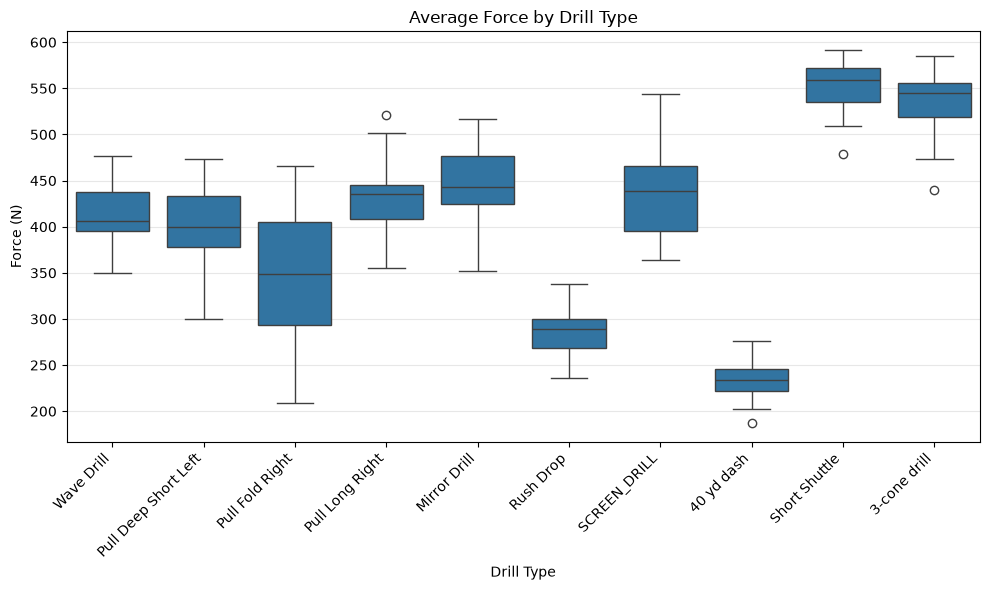

In [93]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=drill_average,
    x='drill_name',
    y='Force'
)

plt.title('Average Force by Drill Type')
plt.xlabel('Drill Type')
plt.ylabel('Force (N)')
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

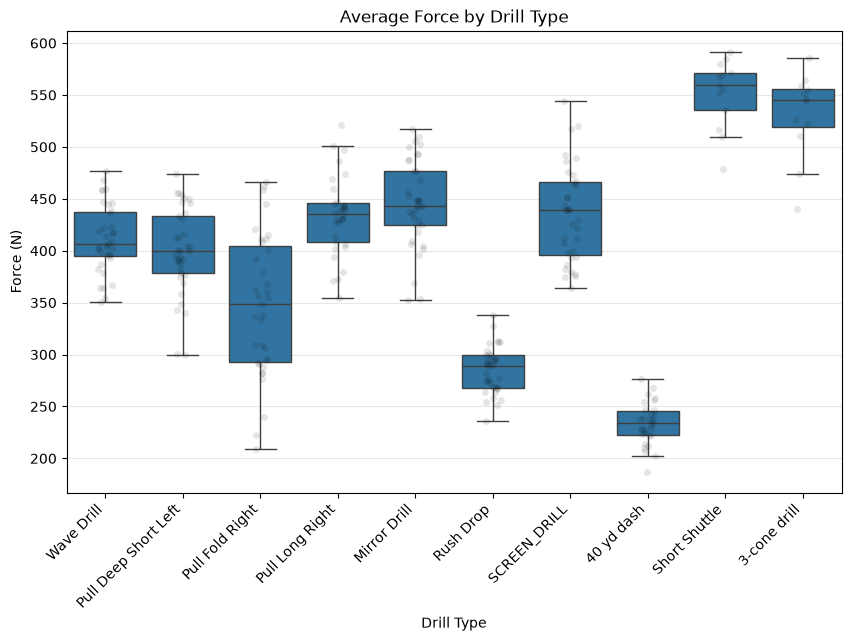

In [96]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=drill_average,
    x='drill_name',
    y='Force',
    showfliers=False
)

sns.stripplot(
    data=drill_average,
    x='drill_name',
    y='Force',
    color='black',
    alpha=0.1
    ,
    jitter=True
)

plt.title('Average Force by Drill Type')
plt.xlabel('Drill Type')
plt.ylabel('Force (N)')
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', alpha=0.3)

plt.show()